# Część A: GeoPandas
---
### Sprawdzenie środowiska i wersji bibliotek

In [1]:
import geopandas as gpd
import rasterio
import shapely

print("geopandas", gpd.__version__)
print("rasterio ", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)
print("shapely  ", shapely.__version__)

geopandas 1.0.1
rasterio  1.4.3 | GDAL 3.9.3
shapely   2.0.7


---
## A1. Geometria i GeoDataFrame od zera

In [2]:
from shapely.geometry import Point, Polygon

rynek = Point(17.9226, 50.6681)          # (x, y) = (longitude, latitude)
square = Polygon([(17.92, 50.66), (17.93, 50.66), (17.93, 50.67), (17.92, 50.67)])

print(rynek)
print(square.area)                       # in "units of the coordinates" - here: square degrees!
print(square.contains(rynek))

POINT (17.9226 50.6681)
0.00010000000000003127
True


In [3]:
import geopandas as gpd

places = gpd.GeoDataFrame(
    {"name": ["Rynek", "Square"]},
    geometry=[rynek, square],
    crs="EPSG:4326",                     # WGS 84 - longitude/latitude in degrees
)
places
print(type(places))
print(places.crs)
print(places.geom_type)

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
0      Point
1    Polygon
dtype: object


---
## A2. Wczytanie surowych danych

In [4]:
import pandas as pd

raw = pd.read_csv("dane/pm25_sensors.csv", parse_dates=["measured_at"])
print(raw.shape)
raw.head(10)

(145, 5)


,sensor_id,lat,lon,pm25,measured_at
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00
3,PM-006,50.674051,NaN,25.7,2026-10-01 08:03:00
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
6,PM-036,50.666829,17.940071,23.7,2026-10-01 08:23:00
7,PM-100,50.694328,17.802222,12.5,2026-10-01 08:56:00
8,PM-092,50.684393,17.794548,9.3,2026-10-01 08:09:00
9,PM-087,50.650288,17.940259,-999.0,2026-10-01 08:56:00


In [5]:
raw[["lat", "lon", "pm25"]].describe()

,lat,lon,pm25
count,142.000000,141.000000,145.000000
mean,49.980869,18.613736,-8.995172
std,4.727557,4.743171,167.401474
min,17.873510,17.785622,-999.000000
25%,50.652463,17.897319,14.500000
50%,50.669682,17.918011,19.100000
75%,50.686753,17.940870,22.500000
max,50.767895,50.677587,35.300000


In [6]:
raw.isna().sum()

sensor_id      0
lat            3
lon            4
pm25           0
measured_at    0
dtype: int64

In [7]:
raw.duplicated().sum()

np.int64(5)

---
## A3. Czyszczenie danych

In [8]:
df = raw.copy()
report = {"input rows": len(df)}

# 1. Duplicates - the same message sent twice
df = df.drop_duplicates()
report["after drop_duplicates"] = len(df)

# 2. Rows without coordinates cannot be placed on a map
df = df.dropna(subset=["lat", "lon"])
report["after dropna"] = len(df)

# 3. Swapped coordinates: in Poland lat is 49-55 and lon is 14-24
swapped = df["lat"].between(14, 24.5) & df["lon"].between(49, 55)
df.loc[swapped, ["lat", "lon"]] = df.loc[swapped, ["lon", "lat"]].to_numpy()
report["swapped rows fixed"] = int(swapped.sum())

# 4. -999 is the sensor's error code, not a measurement
df = df[df["pm25"] >= 0].reset_index(drop=True)
report["clean rows"] = len(df)

report

{'input rows': 145, 'after drop_duplicates': 140, 'after dropna': 134, 'swapped rows fixed': 3, 'clean rows': 130}

In [9]:
df[["lat", "lon", "pm25"]].describe().round(2)

,lat,lon,pm25
count,130.00,130.00,130.00
mean,50.67,17.92,18.86
std,0.03,0.04,5.19
min,50.62,17.79,9.20
25%,50.65,17.90,14.65
50%,50.67,17.92,19.00
75%,50.69,17.94,22.22
max,50.77,18.02,35.30


---
## A4. Z tabeli do GeoDataFrame

In [10]:
sensors = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),   # x = lon, y = lat!
    crs="EPSG:4326",
)
sensors.head()
print(sensors.geom_type.unique())
print(sensors.crs)
print(sensors.total_bounds)              # [minx, miny, maxx, maxy]

['Point']
EPSG:4326
[17.785622 50.616593 18.020378 50.767895]


In [11]:
sensors.explore(column="pm25", cmap="Oranges", marker_kwds={"radius": 6})

---
## A5. Układy współrzędnych

In [12]:
a, b = sensors.geometry.iloc[0], sensors.geometry.iloc[1]
a.distance(b)

0.04530075497163559

In [13]:
sensors_m = sensors.to_crs("EPSG:2180")
print(sensors_m.geometry.iloc[0].distance(sensors_m.geometry.iloc[1]))
sensors_m.head(3)[["sensor_id", "geometry"]]

4906.147424421921


,sensor_id,geometry
0,PM-042,POINT (422754.546 312637.211)
1,PM-106,POINT (423620.153 307808.028)
2,PM-130,POINT (430744.745 308078.679)


In [14]:
from pyproj import Geod

gdansk, zakopane = (18.6466, 54.3520), (19.9496, 49.2992)
pts = gpd.GeoSeries.from_xy([gdansk[0], zakopane[0]], [gdansk[1], zakopane[1]], crs="EPSG:4326")

_, _, true_m = Geod(ellps="WGS84").inv(*gdansk, *zakopane)
print(f"geodesic : {true_m / 1000:8.1f} km")

for crs in ["EPSG:3857", "EPSG:2180"]:
    p = pts.to_crs(crs)
    d = p.iloc[0].distance(p.iloc[1])
    print(f"{crs}: {d / 1000:8.1f} km   error {100 * (d / true_m - 1):+.2f} %")

geodesic :    569.3 km
EPSG:3857:    922.8 km   error +62.09 %
EPSG:2180:    568.9 km   error -0.07 %


---
## A6. Poligony: dzielnice Opola

In [15]:
districts = gpd.read_file("dane/opole_districts.geojson")
print(len(districts), districts.crs)
districts.head()

29 EPSG:4326


,osm_id,name,geometry
0,9709955,Armii Krajowej,"POLYGON ((17.94533 50.68232, 17.94712 50.68404..."
1,9710023,Bierkowice,"POLYGON ((17.84376 50.6998, 17.84415 50.69965,..."
2,9710193,Borki,"POLYGON ((17.87562 50.74302, 17.87767 50.74222..."
3,9710322,Brzezie,"POLYGON ((17.88652 50.75983, 17.88756 50.75843..."
4,9711126,Chabry,"POLYGON ((17.92146 50.67526, 17.92164 50.67542..."


In [16]:
districts = districts.to_crs("EPSG:2180")
districts["area_km2"] = districts.area / 1e6        # m² -> km²

print(f"City area: {districts['area_km2'].sum():.1f} km²")
districts.sort_values("area_km2", ascending=False).head()

City area: 148.8 km²


,osm_id,name,geometry,area_km2
6,9711276,Czarnowąsy,"POLYGON ((420790.396 319539.109, 420754.248 31...",14.116777
10,2732169,Grudzice,"POLYGON ((427076.872 309182.343, 427253.379 30...",12.343554
22,9708643,Wrzoski,"POLYGON ((417245.105 316509.303, 417329.252 31...",11.463066
27,9721684,Świerkle,"POLYGON ((421489.288 322020.575, 422512.041 32...",8.619009
8,2732168,Groszowice,"POLYGON ((427076.872 309182.343, 427186.641 30...",8.023906


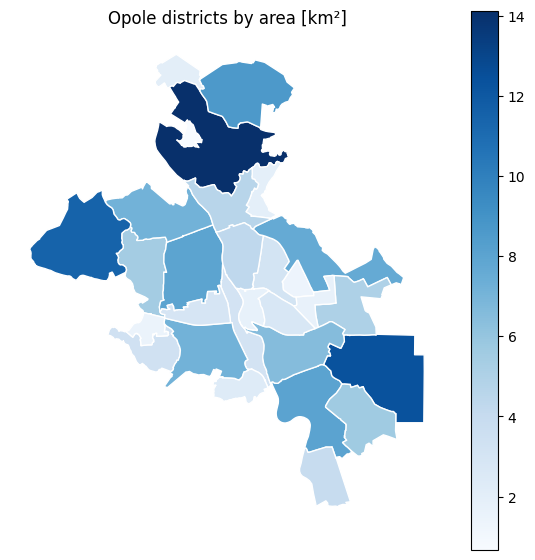

In [17]:
import matplotlib.pyplot as plt

ax = districts.plot(column="area_km2", cmap="Blues", legend=True,
                    edgecolor="white", figsize=(7, 7))
ax.set_title("Opole districts by area [km²]")
ax.set_axis_off()
plt.show()

---
## A7. Złączenie przestrzenne

In [18]:
joined = gpd.sjoin(
    sensors_m,                                   # left: points
    districts[["name", "geometry"]],             # right: polygons (only the columns we need)
    how="left",
    predicate="within",                          # point lies within polygon
)
print(len(joined), joined["name"].isna().sum())
joined[["sensor_id", "pm25", "name"]].head()

130 0


,sensor_id,pm25,name
0,PM-042,23.5,Nadodrze
1,PM-106,12.4,Winów
2,PM-130,19.4,Grudzice
3,PM-025,16.8,Chabry
4,PM-137,14.4,Półwieś


In [19]:
stats = (joined.groupby("name")
               .agg(pm25_mean=("pm25", "mean"), sensor_count=("pm25", "size"))
               .round(1))

summary = districts.merge(stats, on="name", how="left")
summary.sort_values("pm25_mean", ascending=False).head()

,osm_id,name,geometry,area_km2,pm25_mean,sensor_count
18,9720720,Stare Miasto,"POLYGON ((423137.707 312629.565, 423286.828 31...",1.738654,29.6,3.0
26,9720881,Śródmieście,"POLYGON ((424619.006 312507.167, 424633.608 31...",2.805813,26.8,7.0
25,9721785,Zaodrze,"POLYGON ((419715.545 311574.778, 419778.921 31...",2.944668,22.5,6.0
15,9720000,Nadodrze,"POLYGON ((422466.331 312696.733, 422474.477 31...",3.168982,22.4,9.0
24,2730710,Zakrzów,"POLYGON ((422235.989 315159.897, 422390.296 31...",4.308565,20.8,13.0


In [20]:
reliable = summary[summary["sensor_count"] >= 3]
reliable.nlargest(3, "pm25_mean")[["name", "pm25_mean", "sensor_count"]]

,name,pm25_mean,sensor_count
18,Stare Miasto,29.6,3.0
26,Śródmieście,26.8,7.0
25,Zaodrze,22.5,6.0


In [21]:
summary.explore(column="pm25_mean", cmap="Oranges", scheme="quantiles", k=5,
                legend_kwds={"caption": "mean PM2.5 [µg/m³]"},
                missing_kwds={"color": "lightgray", "label": "no sensors"})

---
## A8. Bufory

In [22]:
schools = gpd.read_file("dane/opole_schools.geojson").to_crs("EPSG:2180")

buffers = schools.copy()
buffers["geometry"] = schools.buffer(500)          # metres, because EPSG:2180
buffers.head(3)

,osm_id,name,geometry
0,way/207027259,Niepubliczna Szkoła Podstawowa Nasza Szkoła,"POLYGON ((425250.442 313309.464, 425248.034 31..."
1,way/208494323,Publiczna Szkoła Podstawowa nr 1 im. Obrońców ...,"POLYGON ((424964.042 311369.771, 424961.635 31..."
2,way/452471787,Publiczna Szkoła Podstawowa nr 10 im. Henryka ...,"POLYGON ((422845.594 310511.192, 422843.186 31..."


In [23]:
near_schools = gpd.sjoin(sensors_m, buffers[["name", "geometry"]], predicate="within")

print("schools:", len(schools))
print("schools with a sensor within 500 m:", near_schools["name"].nunique())
print(f"mean PM2.5 near schools: {near_schools['pm25'].mean():.1f} µg/m³")

schools: 19
schools with a sensor within 500 m: 11
mean PM2.5 near schools: 22.3 µg/m³


In [24]:
city = districts.union_all()
coverage = buffers.union_all().intersection(city).area / city.area
print(f"{coverage:.1%} of the city")

9.5% of the city


In [25]:
m = districts.explore(color="gray", style_kwds={"fillOpacity": 0.05}, name="districts")
buffers.explore(m=m, color="orange", name="500 m buffers")
sensors_m.explore(m=m, color="black", marker_kwds={"radius": 3}, name="sensors")
m

---
## A9. Zapis wyników

In [26]:
from pathlib import Path

out = Path("wyniki")
out.mkdir(exist_ok=True)

# GeoPackage: many layers in one file, any CRS - the default choice
summary.to_file(out / "pm25.gpkg", layer="districts", driver="GPKG")
sensors_m.to_file(out / "pm25.gpkg", layer="sensors", driver="GPKG")

# GeoJSON: for web applications - always save it in EPSG:4326
summary.to_crs("EPSG:4326").to_file(out / "pm25_districts.geojson", driver="GeoJSON")

gpd.list_layers(out / "pm25.gpkg")

,name,geometry_type
0,districts,Polygon
1,sensors,Point


In [27]:
check = gpd.read_file(out / "pm25.gpkg", layer="districts")
print(len(check), check.crs)

29 EPSG:2180
